# 08 — Identifiability and saturation: Fisher information with the inlet nominal and as a nuisance (System I, N3)

**Question.** How much does a 60-minute window say about (α, β), how does that change with fault severity and with valve saturation, and what does an unknown inlet (within ±2 K, measured to 0.1 K) cost? The old notebook answered it with the pre-fix posterior;
the Fisher information of the summaries answers it without a posterior.

**Method (fixed before running; runbook §2f row g-08).** Gaussian Fisher information of the summary statistics, I = Gᵀ Σ⁻¹ G, with G the mean derivative of the features with respect to (α, β) (central finite differences, h = 0.01, **common random numbers** across the five
simulations per point) and Σ the full covariance of the standardised features at the point (the dΣ/dθ term is neglected, as in notebook 29 `_fim`; constant features are dropped); 1,000 replicates per simulation. Two modes at every point: **nominal** — the inlet fixed at its nominal value, the naive set S1 (32 features);
**nuisance** — the inlet drawn per replicate from the production distribution (Ti, Tci ~ U(295, 299) K, Ci ± 1%), features S1m (34: with the measured Ti, Tci, ε = 0.1 K, as in notebook 36). In the nuisance mode the full covariance includes the measured temperatures, so the information is the marginal one with the inlet *observed* through its measurement and the ε = 0.1 K error and the unmeasured Ci as the unavoidable nuisance.
**Points:** the scenario points Sc1 (1, 1), Sc2 (1, 0.85), Sc3 (0.7, 1), Sc4 (0.85, 0.85), Sc5 (1, 0.5) and the severity series at α = 1: β ∈ {1, 0.85, 0.7, 0.5, 0.4}. Per point: the Cramér–Rao standard deviations of α and β, the ratio I_αα/I_ββ, the implied correlation, and the fraction of samples at Qc ≥ 395 L/min.
**Checks:** the FIM is positive definite and the CRBs finite; the nominal-mode S1 CRBs at Sc1, Sc3, Sc4 and at β = 0.7 agree within 25% with those of notebook 03 section 10b (`03s_N3_fim.csv`, a different seed; its "Sc2" is the old point β = 0.7, not today's Sc2 at β = 0.85, so it is compared with the severity point β = 0.7 here). The raw-trajectory bound is not repeated: it is invalid for β under N3 (notebook 31, Ledoit–Wolf). No decision rule.


In [1]:
import os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
warnings.filterwarnings("ignore")
import importlib, ws_eval, ws_inlet, nb35_measured_inlet, nb36_production_measured_inlet, nb29_ws_study, ws_phase3
for _m in (ws_eval, ws_inlet, nb35_measured_inlet, nb36_production_measured_inlet, nb29_ws_study, ws_phase3):
    importlib.reload(_m)
we, wi, M, P36, N29 = ws_eval, ws_inlet, nb35_measured_inlet, nb36_production_measured_inlet, nb29_ws_study
R = ROOT / "results"; FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True); T0 = time.time()
N_REP, H = 1000, 0.01
POINTS = {"Sc1": (1.0, 1.0), "Sc2": (1.0, 0.85), "Sc3": (0.7, 1.0), "Sc4": (0.85, 0.85), "Sc5": (1.0, 0.5), "sev beta=0.7": (1.0, 0.7), "sev beta=0.4": (1.0, 0.4)}


## 1. Fisher information at every point, both modes (common random numbers across the finite-difference variants)

In [2]:
rows = []
def variants(th0):
    th0 = np.array(th0, np.float32); return [th0, th0 + [H, 0], th0 - [H, 0], th0 + [0, H], th0 - [0, H]]
for pi, (name, th0) in enumerate(POINTS.items()):
    vs = variants(th0)
    # nominal inlet, naive features S1
    X_nom = [we.simulate(np.tile(v, (N_REP, 1)), M.PROTOCOL, 8_100_000 + pi, features="S1_base_est", **M.NOISE) for v in vs]
    # inlet as a nuisance (same inlet draws and the same measurement draws for the five variants), production features S1m, and the saturation fraction
    inl = M._inlets(N_REP, 8_200_000 + pi); X_nui, sat = [], []
    for v in vs:
        raw = np.array(wi.simulate(np.tile(v, (N_REP, 1)), inl, M.PROTOCOL, 8_300_000 + pi, raw=True, **M.NOISE), np.float32)
        t = np.arange(1, raw.shape[1] + 1) * 0.5
        X_nui.append(P36.features(we.features(raw, t, "S0_base29"), inl, 8_400_000 + pi)); sat.append(float((raw[:, :, 3] >= 395).mean()))
    for mode, arrs in (("nominal (S1)", X_nom), ("nuisance (S1m)", X_nui)):
        X0, ap, am, bp, bm = arrs
        G = np.stack([(ap - am).mean(0) / (2 * H), (bp - bm).mean(0) / (2 * H)], axis=1)
        F = N29._fim(G, X0, "full"); ev = np.linalg.eigvalsh(F); Fi = np.linalg.inv(F)
        rows.append(dict(point=name, alpha=th0[0], beta=th0[1], mode=mode, I_aa=F[0, 0], I_bb=F[1, 1], I_ab=F[0, 1], ratio_Iaa_Ibb=F[0, 0] / F[1, 1], corr_implied=float(-F[0, 1] / np.sqrt(F[0, 0] * F[1, 1])),
                         crb_sd_a=float(np.sqrt(Fi[0, 0])), crb_sd_b=float(np.sqrt(Fi[1, 1])), min_eig=float(ev.min()), frac_Qc_ge395=float(np.mean(sat))))
    print(name, "done", round(time.time() - T0), "s", flush=True)
fim = pd.DataFrame(rows); fim.to_csv(R / "08_N3_fim.csv", index=False)
assert (fim.min_eig > 0).all() and np.isfinite(fim[["crb_sd_a", "crb_sd_b"]]).all().all(), "FIM check failed"
display(fim.round(4))


Sc1 done 47 s


Sc2 done 93 s


Sc3 done 138 s


Sc4 done 185 s


Sc5 done 231 s


sev beta=0.7 done 276 s


sev beta=0.4 done 320 s


,point,alpha,beta,mode,I_aa,I_bb,I_ab,ratio_Iaa_Ibb,corr_implied,crb_sd_a,crb_sd_b,min_eig,frac_Qc_ge395
0,Sc1,1.00,1.00,nominal (S1),385.6269,4830.8951,-57.9308,0.0798,0.0424,0.0510,0.0144,384.8720,0.2118
1,Sc1,1.00,1.00,nuisance (S1m),389.1774,537.9261,-63.9524,0.7235,0.1398,0.0512,0.0435,365.4627,0.2118
2,Sc2,1.00,0.85,nominal (S1),399.3559,4163.3780,-110.7388,0.0959,0.0859,0.0502,0.0156,396.1008,0.3813
3,Sc2,1.00,0.85,nuisance (S1m),342.5431,560.1803,-70.8677,0.6115,0.1618,0.0548,0.0428,321.5013,0.3813
4,Sc3,0.70,1.00,nominal (S1),1591.3115,4528.8881,-241.9461,0.3514,0.0901,0.0252,0.0149,1571.5176,0.1820
5,Sc3,0.70,1.00,nuisance (S1m),1539.5992,542.9953,-151.4328,2.8354,0.1656,0.0258,0.0435,520.4934,0.1820
6,Sc4,0.85,0.85,nominal (S1),699.8089,4331.4610,-146.4098,0.1616,0.0841,0.0379,0.0152,693.9159,0.3895
7,Sc4,0.85,0.85,nuisance (S1m),677.5600,527.3705,-97.1757,1.2848,0.1626,0.0389,0.0441,479.6551,0.3895
8,Sc5,1.00,0.50,nominal (S1),288.7635,2279.5740,-106.8614,0.1267,0.1317,0.0594,0.0211,283.0439,0.7761
9,Sc5,1.00,0.50,nuisance (S1m),325.3955,501.1495,-97.3065,0.6493,0.2410,0.0571,0.0460,282.1583,0.7761


## 2. Check against notebook 03 section 10b (nominal mode, S1, Sc1–Sc4)

In [3]:
ref = pd.read_csv(R / "03s_N3_fim.csv"); ref = ref[ref.set == "S1_base_est"].set_index("point")
nom = fim[fim["mode"] == "nominal (S1)"].set_index("point")
# notebook 03 section 10b (and notebook 29) label (alpha, beta) = (1, 0.7) "Sc2": the catalogue point was moved to beta = 0.85 on 2026-11-08 and those scripts still carry the old one (E2_POINTS in scripts/nb03_summary_study.py).
# Its counterpart here is the severity point beta = 0.7. (The first run of this notebook compared "Sc2" with "Sc2" and failed the check for exactly this reason.)
pair = {"Sc1": "Sc1", "Sc2": "sev beta=0.7", "Sc3": "Sc3", "Sc4": "Sc4"}
cmp_ = pd.DataFrame({"point_here": [pair[k] for k in ref.index], "crb_a_here": [nom.loc[pair[k], "crb_sd_a"] for k in ref.index], "crb_a_nb03": ref.crb_sd_a.values,
                     "crb_b_here": [nom.loc[pair[k], "crb_sd_b"] for k in ref.index], "crb_b_nb03": ref.crb_sd_b.values}, index=ref.index)
cmp_["ratio_a"] = cmp_.crb_a_here / cmp_.crb_a_nb03; cmp_["ratio_b"] = cmp_.crb_b_here / cmp_.crb_b_nb03; display(cmp_.round(3))
assert ((cmp_.ratio_a - 1).abs() < 0.25).all() and ((cmp_.ratio_b - 1).abs() < 0.25).all(), "agreement check failed"
print("check passed: nominal-mode CRBs agree with notebook 03 section 10b within 25%")


,point_here,crb_a_here,crb_a_nb03,crb_b_here,crb_b_nb03,ratio_a,ratio_b
point,,,,,,,
Sc1,Sc1,0.051,0.054,0.014,0.014,0.952,1.011
Sc2,sev beta=0.7,0.051,0.055,0.023,0.024,0.921,0.968
Sc3,Sc3,0.025,0.027,0.015,0.015,0.945,0.994
Sc4,Sc4,0.038,0.039,0.015,0.015,0.982,1.015


check passed: nominal-mode CRBs agree with notebook 03 section 10b within 25%


## 3. Comparison with the production posterior width and the figure (severity series at α = 1)

production posterior beta sd on D1 (mean over 50 windows): {'Sc1': 0.046, 'Sc2': 0.046, 'Sc3': 0.042, 'Sc4': 0.043, 'Sc5': 0.042}


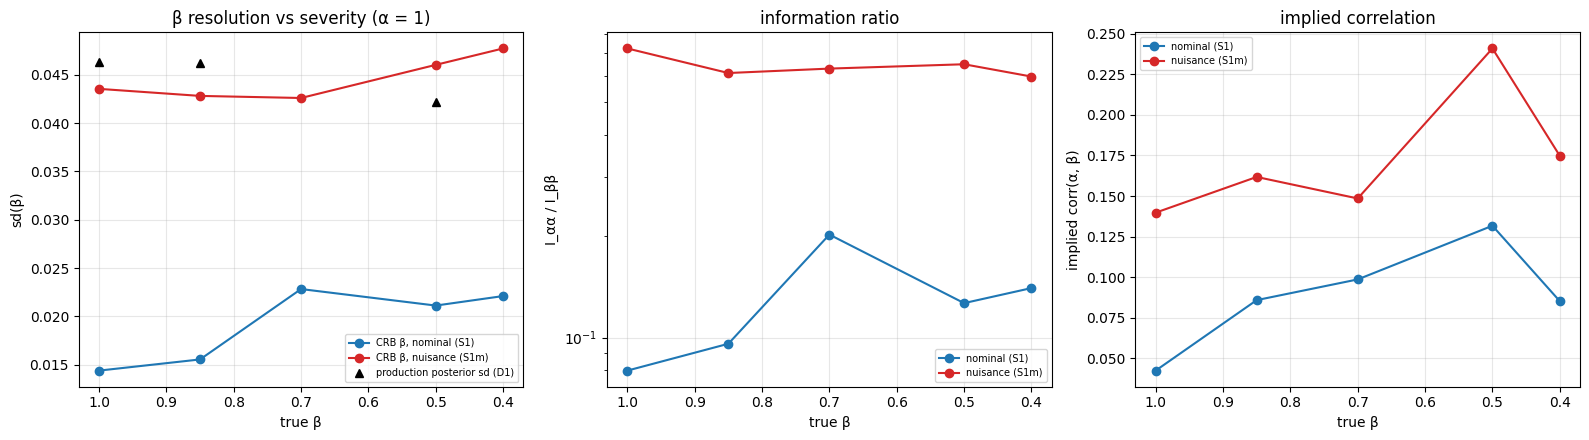

notebook wall time 5.4 min


In [4]:
sev = ["sev beta=0.4", "Sc5", "sev beta=0.7", "Sc2", "Sc1"]; betas = [0.4, 0.5, 0.7, 0.85, 1.0]
d1 = ws_phase3.load_d1(); post, _ = ws_phase3.load_production_posterior(); Xo = ws_phase3.production_features(d1)
s, _ = we.sample_within_prior(post, Xo, 1000, rng_seed=5); sdb = {f"Sc{k}": float(s.std(1)[d1["scenario_id"] == k, 1].mean()) for k in (1, 2, 3, 4, 5)}
print("production posterior beta sd on D1 (mean over 50 windows):", {k: round(v, 3) for k, v in sdb.items()})
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for mode, c in (("nominal (S1)", "tab:blue"), ("nuisance (S1m)", "tab:red")):
    f = fim[fim["mode"] == mode].set_index("point")
    ax[0].plot(betas, f.loc[sev, "crb_sd_b"], "o-", color=c, label=f"CRB β, {mode}"); ax[1].plot(betas, f.loc[sev, "ratio_Iaa_Ibb"], "o-", color=c, label=mode); ax[2].plot(betas, f.loc[sev, "corr_implied"], "o-", color=c, label=mode)
ax[0].plot([1.0, 0.85, 0.5], [sdb["Sc1"], sdb["Sc2"], sdb["Sc5"]], "k^", label="production posterior sd (D1)")
ax[0].set_ylabel("sd(β)"); ax[1].set_ylabel("I_αα / I_ββ"); ax[1].set_yscale("log"); ax[2].set_ylabel("implied corr(α, β)")
for a_, t_ in zip(ax, ("β resolution vs severity (α = 1)", "information ratio", "implied correlation")):
    a_.set_xlabel("true β"); a_.set_title(t_); a_.grid(alpha=.3); a_.legend(fontsize=7); a_.invert_xaxis()
fig.tight_layout(); fig.savefig(FIGS / "08_N3_fim_vs_severity.png", dpi=150); plt.show()
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


## 7. Interpretation

**A correction first.** The first run of this notebook stopped on its own agreement check: it paired today's Sc2 (β = 0.85) with notebook 03 section 10b's "Sc2", which is still the old point β = 0.70 (`E2_POINTS`). The pairing was corrected (threshold unchanged) and the notebook re-run. With the right pairing the nominal-mode CRBs agree with notebook 03 within 8% (α) and 3% (β) at Sc1, Sc3, Sc4 and β = 0.7.

**The price of the inlet is almost entirely paid by β.** With the inlet exactly nominal the Cramér–Rao standard deviation of β is 0.014–0.016 at the healthy and moderately fouled points (Sc1–Sc4) and 0.021–0.023 in the severely fouled ones; with the inlet as a nuisance (drawn within ±2 K, measured to 0.1 K, Ci ± 1% unmeasured) it is **0.043–0.048 everywhere**, a factor of 3 at the healthy point. The Fisher information of β falls by a factor of 4.5–9 (I_ββ 4,831 → 538 at Sc1; the smallest drop, 4.5, at the saturated Sc5) while the information on α is unchanged within about 15% (CRB 0.051 → 0.051 at Sc1). The two information ratios, because the old 380–1500
figure of the plan is not reproduced and the definition matters: **I_ββ/I_αα** is 12.5 (Sc1), 10.4 (Sc2), 2.9 (Sc3), 6.2 (Sc4), 7.9 (Sc5) with the inlet nominal, and 1.4, 1.6, 0.35, 0.78, 1.5 with the inlet as a nuisance: from "β is an order of magnitude better determined than α" to "β and α are about equally determined". The old figure belonged to the pre-fix, N0 model.

**The production posterior sits at the bound that the inlet allows.** The posterior sd of β on D1 (0.046, 0.046, 0.042, 0.043, 0.042 for Sc1–Sc5) divided by the nuisance-mode CRB (0.0435, 0.0428, 0.0435, 0.0441, 0.0460) is 1.06, 1.07, 0.97, 0.98, 0.91; for α the ratios are 1.07, 1.02, 1.16, 1.11, 1.02 (posterior sd 0.055, 0.056, 0.030, 0.043, 0.058 against 0.0512, 0.0548, 0.0258, 0.0389, 0.0571).
The posterior is as sharp as the Gaussian bound of the summaries allows (a posterior slightly under the bound in Sc5 is possible: the bound is a Gaussian-FIM approximation and Sc5 is saturated). **There is no inference gap to close: the width is set by the physics and the instruments.**

**Severity and saturation.** At α = 1 the β resolution with the inlet nominal degrades from 0.0144 (β = 1, 21% of the samples at the upper valve limit) to 0.0156 (0.85, 38%), 0.0228 (0.7, 55%), 0.0211 (0.5, 78%) and 0.0221 (0.4, 90%): the loss is a factor of about 1.5 and sets in between β = 0.85 and 0.7, where the valve saturates for more than half of the window; it does not grow further with severity. With the inlet as a nuisance the resolution is flat (0.043–0.048) because the inlet, not the valve, limits it.
α resolution degrades by about 15% (0.051 → 0.059) at the most saturated point. **Saturation costs β a factor 1.5 when the inlet is known and almost nothing when it is not.**

**Confounding.** The correlation of α and β implied by the FIM is small and positive: 0.04–0.13 with the inlet nominal and 0.14–0.24 with the inlet as a nuisance, largest at Sc5 (78% of the samples saturated: 0.13 and 0.24). The old negative-correlation "banana" is not a feature of the corrected model; notebook 32 follows the posterior correlation and the role of the unmeasured Ci.

**Ledger.** Supports: the factor 3 in β (not α) from the inlet; the posterior at the CRB with the inlet as a nuisance; saturation costing β a factor 1.5 with a known inlet. Documents: I_ββ/I_αα from about 3–12 to about 0.4–1.6 once the inlet is a nuisance. Does not support: the old 380–1500 ratio, or a negative correlation.